# Credit Risk Modeling for Thin-File Borrowers
### Home Credit Default Risk: baseline, challenger model, "no bureau data" experiment, fairness check and scorecard

**Goal:** predict which loan applicants will have repayment difficulties, using a dataset built around people with little or no credit history. This is the same problem a fair-credit startup solves.

**What this notebook covers**
1. Load and explore the data
2. Clean known data issues
3. Engineer affordability and stability features
4. Baseline model: logistic regression
5. Challenger model: LightGBM (gradient boosting)
6. **Thin-file experiment:** how good is the model *without* credit-bureau-style data?
7. Calibration and risk bands
8. Explainability (feature importance and SHAP)
9. Fairness check by gender and age group
10. **Age experiment:** does removing age features reduce the age gap?
11. Convert probabilities into a points-based credit score
12. Summary of results

**Before running:** on Kaggle, add the *Home Credit Default Risk* competition data as an input. On a laptop, see the setup cell below.

## 0. Setup

**Get the data**
1. Create a free Kaggle account at kaggle.com.
2. Open the competition page *Home Credit Default Risk*, go to the **Data** tab, and accept the competition rules.
3. Download `application_train.csv` (about 160 MB) and put it in a folder called `data/` next to this notebook.

**Install packages** (run once in your terminal):
```
pip install pandas numpy scikit-learn lightgbm shap matplotlib
```

Tip: if your laptop is slow, set `SAMPLE_ROWS` below to e.g. `100000` while experimenting, then set it back to `None` for final results.

In [40]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve

import lightgbm as lgb

import os

# Finds the data automatically on Kaggle or on your laptop
CANDIDATE_PATHS = [
    "/kaggle/input/competitions/home-credit-default-risk/application_train.csv",
    "/kaggle/input/home-credit-default-risk/application_train.csv",
    "data/application_train.csv",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), CANDIDATE_PATHS[-1])
print("Using data file:", DATA_PATH)

SAMPLE_ROWS = None      # e.g. 100000 for quick experiments
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

Using data file: /kaggle/input/competitions/home-credit-default-risk/application_train.csv


## 1. Load and explore the data

In [41]:
df = pd.read_csv(DATA_PATH)
if SAMPLE_ROWS:
    df = df.sample(n=min(SAMPLE_ROWS, len(df)), random_state=RANDOM_STATE)

print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
print(f"Default rate (TARGET = 1): {df['TARGET'].mean():.2%}")
df.head()

Rows: 307,511   Columns: 122
Default rate (TARGET = 1): 8.07%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [42]:
# Missing values: which columns are mostly empty?
missing = df.isna().mean().sort_values(ascending=False)
print("Columns more than 50% missing:", (missing > 0.5).sum())
missing.head(15).to_frame("share_missing")

Columns more than 50% missing: 41


,share_missing
COMMONAREA_AVG,0.698723
COMMONAREA_MODE,0.698723
COMMONAREA_MEDI,0.698723
NONLIVINGAPARTMENTS_MEDI,0.694330
NONLIVINGAPARTMENTS_MODE,0.694330
NONLIVINGAPARTMENTS_AVG,0.694330
FONDKAPREMONT_MODE,0.683862
LIVINGAPARTMENTS_AVG,0.683550
LIVINGAPARTMENTS_MEDI,0.683550
LIVINGAPARTMENTS_MODE,0.683550


In [43]:
# Default rate by a few key categories
for col in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_CONTRACT_TYPE"]:
    if col in df.columns:
        display(df.groupby(col)["TARGET"].agg(["mean", "count"])
                  .rename(columns={"mean": "default_rate"})
                  .sort_values("default_rate", ascending=False))

,default_rate,count
NAME_INCOME_TYPE,,
Maternity leave,0.400000,5
Unemployed,0.363636,22
Working,0.095885,158774
Commercial associate,0.074843,71617
State servant,0.057550,21703
Pensioner,0.053864,55362
Businessman,0.000000,10
Student,0.000000,18


,default_rate,count
NAME_EDUCATION_TYPE,,
Lower secondary,0.109277,3816
Secondary / secondary special,0.089399,218391
Incomplete higher,0.084850,10277
Higher education,0.053551,74863
Academic degree,0.018293,164


,default_rate,count
NAME_CONTRACT_TYPE,,
Cash loans,0.083459,278232
Revolving loans,0.054783,29279


## 2. Clean known data issues

- `DAYS_EMPLOYED` uses **365243** as a placeholder (mostly pensioners and unemployed). We flag it and set it to missing.
- `DAYS_*` columns are negative day counts relative to the application. We convert age and employment to years.
- `CODE_GENDER` has a few `XNA` values. We set them to missing.

In [44]:
df = df.copy()
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
df["YEARS_EMPLOYED"] = -df["DAYS_EMPLOYED"] / 365.25

if "CODE_GENDER" in df.columns:
    df.loc[df["CODE_GENDER"] == "XNA", "CODE_GENDER"] = np.nan

print("Anomalous employment rows:", df["DAYS_EMPLOYED_ANOM"].sum())

Anomalous employment rows: 55374


## 3. Feature engineering

These features capture **affordability** and **stability**, the same ideas you would use with alternative data (mobile money, sales records) in the startup.

In [45]:
eps = 1e-6
df["CREDIT_TO_INCOME"]   = df["AMT_CREDIT"]  / (df["AMT_INCOME_TOTAL"] + eps)
df["ANNUITY_TO_INCOME"]  = df["AMT_ANNUITY"] / (df["AMT_INCOME_TOTAL"] + eps)
df["CREDIT_TERM_MONTHS"] = df["AMT_CREDIT"]  / (df["AMT_ANNUITY"] + eps)
df["CREDIT_TO_GOODS"]    = df["AMT_CREDIT"]  / (df["AMT_GOODS_PRICE"] + eps)
df["EMPLOYED_TO_AGE"]    = df["YEARS_EMPLOYED"] / (df["AGE_YEARS"] + eps)
df["INCOME_PER_PERSON"]  = df["AMT_INCOME_TOTAL"] / (df["CNT_FAM_MEMBERS"].fillna(1) + eps)

ext_cols = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
if ext_cols:
    df["EXT_SOURCE_MEAN"] = df[ext_cols].mean(axis=1)

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df[["CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TERM_MONTHS", "EMPLOYED_TO_AGE"]].describe()

,CREDIT_TO_INCOME,ANNUITY_TO_INCOME,CREDIT_TERM_MONTHS,EMPLOYED_TO_AGE
count,307511.000000,307499.000000,307499.000000,252137.000000
mean,3.957570,0.180930,21.612322,0.156861
std,2.689728,0.094574,7.823823,0.133549
min,0.004808,0.000224,8.036674,-0.000000
25%,2.018667,0.114782,15.614496,0.056099
50%,3.265067,0.162833,20.000000,0.118733
75%,5.159880,0.229067,27.099985,0.219170
max,84.736842,1.875965,45.305079,0.728811


## 4. Prepare features and split the data

**Protected attributes are excluded from model inputs.** `CODE_GENDER` is kept aside only to *test* fairness later. Age is used in the model here because it is common in credit models, but note that some jurisdictions restrict how age can be used. Check local rules for any real product.

We split 60% train, 20% validation, 20% test. (Real credit models should use *out-of-time* validation, i.e. test on later applications. This dataset has no dates, so we use a random stratified split and note the limitation.)

In [46]:
PROTECTED = ["CODE_GENDER"]
ID_TARGET = ["SK_ID_CURR", "TARGET"]

# Drop columns that are almost entirely empty
too_empty = missing[missing > 0.85].index.tolist()

feature_cols = [c for c in df.columns if c not in ID_TARGET + PROTECTED + too_empty]
X = df[feature_cols]
y = df["TARGET"]
protected = df[PROTECTED].copy()
protected["AGE_YEARS"] = df["AGE_YEARS"]

X_train, X_temp, y_train, y_temp, p_train, p_temp = train_test_split(
    X, y, protected, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test, p_valid, p_test = train_test_split(
    X_temp, y_temp, p_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"Train {len(X_train):,} | Valid {len(X_valid):,} | Test {len(X_test):,}")
print(f"Numeric features: {len(num_cols)} | Categorical features: {len(cat_cols)}")

Train 184,506 | Valid 61,502 | Test 61,503
Numeric features: 114 | Categorical features: 15


### Evaluation helpers

- **AUC**: probability the model ranks a random defaulter as riskier than a random non-defaulter (0.5 = random, 1.0 = perfect).
- **Gini** = 2 x AUC - 1: the standard credit industry version.
- **KS**: maximum separation between the score distributions of defaulters and non-defaulters.
- **Brier score**: accuracy of the probabilities themselves (lower is better).

In [47]:
def evaluate(name, y_true, p):
    auc = roc_auc_score(y_true, p)
    fpr, tpr, _ = roc_curve(y_true, p)
    return {"model": name,
            "AUC": round(auc, 4),
            "Gini": round(2 * auc - 1, 4),
            "KS": round(np.max(tpr - fpr), 4),
            "Brier": round(brier_score_loss(y_true, p), 4)}

results = []

## 5. Baseline: logistic regression

Simple, transparent and trusted by lenders and regulators. Every serious credit model should be compared against one.

In [48]:
def make_preprocessor(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01))]), cat),
    ])

logreg = Pipeline([
    ("prep", make_preprocessor(num_cols, cat_cols)),
    ("model", LogisticRegression(max_iter=2000, C=0.1)),
])
logreg.fit(X_train, y_train)

p_valid_lr = logreg.predict_proba(X_valid)[:, 1]
results.append(evaluate("Logistic regression (valid)", y_valid, p_valid_lr))
pd.DataFrame(results)

,model,AUC,Gini,KS,Brier
0,Logistic regression (valid),0.7445,0.489,0.3644,0.0686


## 6. Challenger: LightGBM

Gradient boosting usually captures non-linear patterns better. We use early stopping on the validation set to avoid overfitting.

In [49]:
def to_lgb(frame, cats):
    out = frame.copy()
    for c in cats:
        out[c] = out[c].astype("category")
    return out

Xtr_l, Xva_l, Xte_l = (to_lgb(X_train, cat_cols), to_lgb(X_valid, cat_cols), to_lgb(X_test, cat_cols))

lgb_params = dict(n_estimators=2000, learning_rate=0.03, num_leaves=31,
                  min_child_samples=100, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.7, reg_lambda=1.0,
                  random_state=RANDOM_STATE, verbose=-1)

gbm = lgb.LGBMClassifier(**lgb_params)
gbm.fit(Xtr_l, y_train, eval_set=[(Xva_l, y_valid)], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)])

p_valid_gbm = gbm.predict_proba(Xva_l)[:, 1]
results.append(evaluate("LightGBM (valid)", y_valid, p_valid_gbm))
print("Best iteration:", gbm.best_iteration_)
pd.DataFrame(results)

Best iteration: 752


,model,AUC,Gini,KS,Brier
0,Logistic regression (valid),0.7445,0.4890,0.3644,0.0686
1,LightGBM (valid),0.7646,0.5292,0.3957,0.0673


## 7. Thin-file experiment: no credit bureau data

This is the experiment most relevant to the startup idea.

`EXT_SOURCE_1/2/3` are normalized scores from **external data sources** (similar to bureau scores), and `AMT_REQ_CREDIT_BUREAU_*` count credit bureau enquiries. People with no credit history would not have this information.

**Question:** how much predictive power remains using only application, income, employment, household and behavioral data?

In [50]:
bureau_like = [c for c in X.columns if c.startswith("EXT_SOURCE") or c.startswith("AMT_REQ_CREDIT_BUREAU")]
print("Removed columns:", bureau_like)

thin_cols = [c for c in X.columns if c not in bureau_like]
thin_cat = [c for c in cat_cols if c in thin_cols]

gbm_thin = lgb.LGBMClassifier(**lgb_params)
gbm_thin.fit(to_lgb(X_train[thin_cols], thin_cat), y_train,
             eval_set=[(to_lgb(X_valid[thin_cols], thin_cat), y_valid)], eval_metric="auc",
             callbacks=[lgb.early_stopping(100, verbose=False)])

p_valid_thin = gbm_thin.predict_proba(to_lgb(X_valid[thin_cols], thin_cat))[:, 1]
results.append(evaluate("LightGBM, no bureau data (valid)", y_valid, p_valid_thin))
pd.DataFrame(results)

Removed columns: ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'EXT_SOURCE_MEAN']


,model,AUC,Gini,KS,Brier
0,Logistic regression (valid),0.7445,0.4890,0.3644,0.0686
1,LightGBM (valid),0.7646,0.5292,0.3957,0.0673
2,"LightGBM, no bureau data (valid)",0.7131,0.4261,0.3104,0.0701


**How to read this:** the gap between the full model and the "no bureau data" model shows how much lenders lose when they can't see a credit history. The remaining Gini shows how much *alternative* information can still separate good and bad borrowers. In your write-up, this is the core argument for your startup: *alternative data recovers a meaningful share of predictive power for people without credit files.*

## 8. Final test-set results

The test set was not used for training or early stopping, so this is the honest estimate of performance.

In [51]:
p_test_lr   = logreg.predict_proba(X_test)[:, 1]
p_test_gbm  = gbm.predict_proba(Xte_l)[:, 1]
p_test_thin = gbm_thin.predict_proba(to_lgb(X_test[thin_cols], thin_cat))[:, 1]

test_results = pd.DataFrame([
    evaluate("Logistic regression", y_test, p_test_lr),
    evaluate("LightGBM", y_test, p_test_gbm),
    evaluate("LightGBM, no bureau data", y_test, p_test_thin),
])
test_results

,model,AUC,Gini,KS,Brier
0,Logistic regression,0.7522,0.5044,0.3739,0.0683
1,LightGBM,0.7690,0.5380,0.4019,0.0673
2,"LightGBM, no bureau data",0.7164,0.4327,0.3220,0.0704


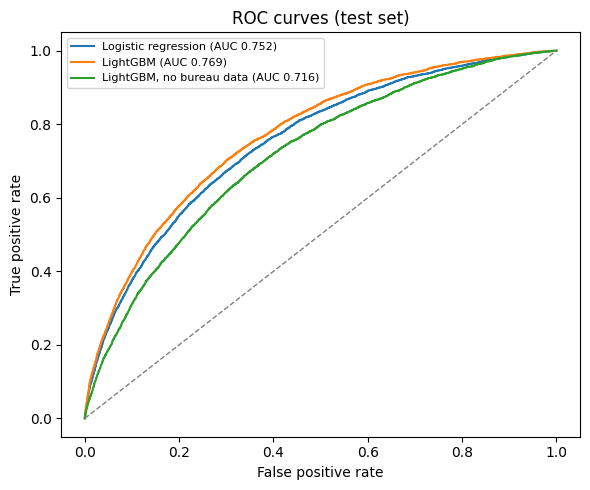

In [52]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [("Logistic regression", p_test_lr), ("LightGBM", p_test_gbm),
                ("LightGBM, no bureau data", p_test_thin)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves (test set)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Calibration and risk bands

A lender prices loans from predicted probabilities, so a "10% risk" should mean roughly 10% of those borrowers default. The decile table also shows how well the score ranks risk: default rates should rise steadily from the safest to the riskiest band.

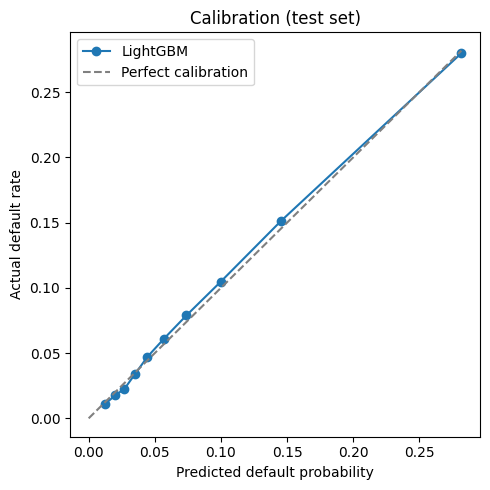

,applicants,avg_predicted_pd,actual_default_rate
risk_decile,,,
1,6151,1.22%,1.09%
2,6150,2.01%,1.76%
3,6150,2.70%,2.26%
4,6150,3.49%,3.37%
5,6151,4.44%,4.71%
6,6150,5.67%,6.08%
7,6150,7.39%,7.89%
8,6150,9.98%,10.47%
9,6150,14.54%,15.12%


In [53]:
prob_true, prob_pred = calibration_curve(y_test, p_test_gbm, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(prob_pred, prob_true, "o-", label="LightGBM")
ax.plot([0, prob_pred.max()], [0, prob_pred.max()], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted default probability"); ax.set_ylabel("Actual default rate")
ax.set_title("Calibration (test set)"); ax.legend()
plt.tight_layout(); plt.show()

bands = pd.DataFrame({"pd": p_test_gbm, "default": y_test.values})
bands["risk_decile"] = pd.qcut(bands["pd"].rank(method="first"), 10, labels=range(1, 11))
decile_table = bands.groupby("risk_decile", observed=True).agg(
    applicants=("default", "size"),
    avg_predicted_pd=("pd", "mean"),
    actual_default_rate=("default", "mean"))
decile_table.style.format({"avg_predicted_pd": "{:.2%}", "actual_default_rate": "{:.2%}"})

## 10. Explainability

Lenders and regulators need to know *why* the model makes a decision. We look at overall feature importance, then SHAP values, which show how each feature pushes an individual prediction up or down.

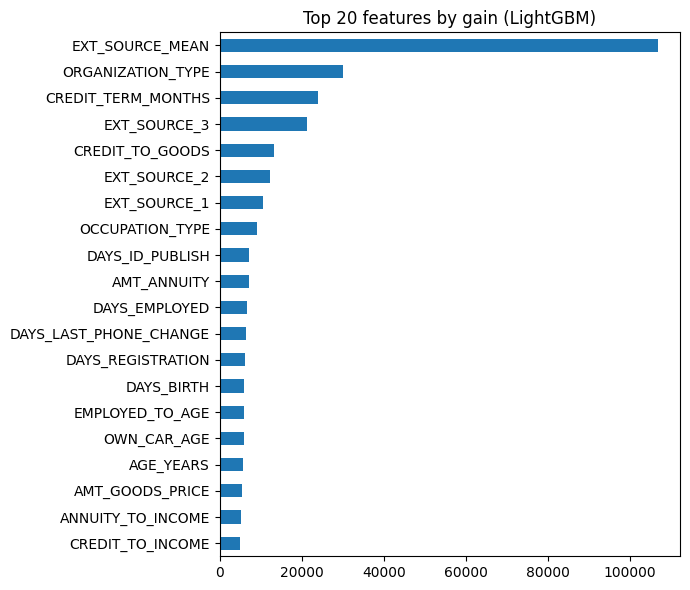

In [54]:
imp = (pd.Series(gbm.booster_.feature_importance(importance_type="gain"), index=Xtr_l.columns)
         .sort_values(ascending=False).head(20))
fig, ax = plt.subplots(figsize=(7, 6))
imp[::-1].plot.barh(ax=ax)
ax.set_title("Top 20 features by gain (LightGBM)")
plt.tight_layout(); plt.show()

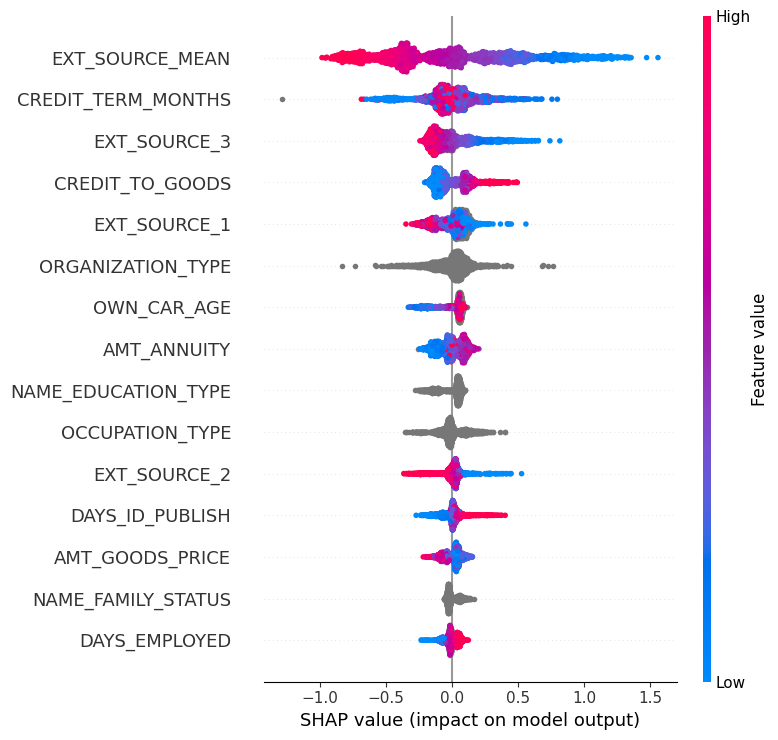

In [55]:
try:
    import shap
    sample = Xte_l.sample(n=min(2000, len(Xte_l)), random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(gbm)
    shap_values = explainer.shap_values(sample)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    shap.summary_plot(shap_values, sample, max_display=15, show=True)
except ImportError:
    print("Install shap (pip install shap) to see SHAP explanations.")

## 11. Fairness check

We check whether the model treats groups differently, even though gender was **not** a model input (other features can act as proxies).

We simulate a lending policy: **approve the safest 80% of applicants.** Then, for each group, we compare:
- **Approval rate:** share of the group approved
- **Default rate among approved:** are approved borrowers in each group equally safe?
- **False rejection rate:** share of people who *would have repaid* but were rejected. This is the most important harm in financial inclusion.

Large gaps are a signal to investigate, not an automatic verdict. Document thresholds before looking at results.

In [56]:
APPROVAL_SHARE = 0.80
cutoff = np.quantile(p_test_gbm, APPROVAL_SHARE)

fair = p_test.copy()
fair["pd"] = p_test_gbm
fair["default"] = y_test.values
fair["approved"] = (fair["pd"] <= cutoff).astype(int)
fair["AGE_GROUP"] = pd.cut(fair["AGE_YEARS"], bins=[0, 30, 45, 60, 120],
                           labels=["Under 30", "30-44", "45-59", "60+"], right=False)

def fairness_table(frame, group_col):
    rows = []
    for g, d in frame.dropna(subset=[group_col]).groupby(group_col, observed=True):
        good = d[d["default"] == 0]
        rows.append({
            group_col: g,
            "applicants": len(d),
            "actual_default_rate": d["default"].mean(),
            "approval_rate": d["approved"].mean(),
            "default_rate_if_approved": d.loc[d["approved"] == 1, "default"].mean(),
            "false_rejection_rate": 1 - good["approved"].mean(),
        })
    t = pd.DataFrame(rows).set_index(group_col)
    return t.style.format({c: "{:.2%}" for c in t.columns if c != "applicants"})

print(f"Policy: approve applicants with predicted PD <= {cutoff:.2%} (safest {APPROVAL_SHARE:.0%})")
display(fairness_table(fair, "CODE_GENDER"))
display(fairness_table(fair, "AGE_GROUP"))

Policy: approve applicants with predicted PD <= 11.72% (safest 80%)


,applicants,actual_default_rate,approval_rate,default_rate_if_approved,false_rejection_rate
CODE_GENDER,,,,,
F,40345,6.96%,83.11%,4.26%,14.47%
M,21158,10.20%,74.06%,5.66%,22.19%


,applicants,actual_default_rate,approval_rate,default_rate_if_approved,false_rejection_rate
AGE_GROUP,,,,,
Under 30,8975,11.51%,65.36%,6.12%,30.66%
30-44,24664,8.96%,77.10%,4.87%,19.44%
45-59,20778,6.65%,85.17%,4.33%,12.71%
60+,7086,4.81%,93.47%,3.97%,5.71%


**Questions to discuss in your write-up**
- Do approval rates differ mainly because actual default rates differ, or does the model add extra disparity?
- Are good borrowers in one group falsely rejected much more often than in another?
- Would removing or constraining certain features (for example, those correlated with gender) reduce gaps, and what would it cost in accuracy?

## 11b. Age experiment: does removing age features reduce the age gap?

The fairness check shows the largest disparity by age: young applicants who would have repaid are falsely rejected far more often than older applicants. Young people are often thin-file borrowers, so this matters for financial inclusion.

Here we retrain LightGBM **without the explicit age features** (`DAYS_BIRTH`, `AGE_YEARS`, `EMPLOYED_TO_AGE`) and compare:
1. Accuracy: how much predictive power do we lose?
2. Fairness: does the false rejection gap between age groups shrink?

**Expect a lesson here.** Other features such as employment length, years since registration, ID age and car age are correlated with age, so they can act as *proxies*. Removing a sensitive variable does not automatically remove its influence.

In [57]:
age_feats = [c for c in ["DAYS_BIRTH", "AGE_YEARS", "EMPLOYED_TO_AGE"] if c in X.columns]
noage_cols = [c for c in X.columns if c not in age_feats]
noage_cat = [c for c in cat_cols if c in noage_cols]
print("Removed features:", age_feats)

gbm_noage = lgb.LGBMClassifier(**lgb_params)
gbm_noage.fit(to_lgb(X_train[noage_cols], noage_cat), y_train,
              eval_set=[(to_lgb(X_valid[noage_cols], noage_cat), y_valid)], eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])
p_test_noage = gbm_noage.predict_proba(to_lgb(X_test[noage_cols], noage_cat))[:, 1]

age_results = pd.DataFrame([
    evaluate("LightGBM (with age)", y_test, p_test_gbm),
    evaluate("LightGBM, no age features", y_test, p_test_noage),
])
display(age_results)

Removed features: ['DAYS_BIRTH', 'AGE_YEARS', 'EMPLOYED_TO_AGE']


,model,AUC,Gini,KS,Brier
0,LightGBM (with age),0.7690,0.5380,0.4019,0.0673
1,"LightGBM, no age features",0.7665,0.5331,0.4013,0.0675


In [58]:
fair_noage = fair.copy()
fair_noage["pd"] = p_test_noage
fair_noage["approved"] = (fair_noage["pd"] <= np.quantile(p_test_noage, APPROVAL_SHARE)).astype(int)

def false_rejection_by_group(frame, group_col):
    good = frame[frame["default"] == 0]
    return 1 - good.groupby(group_col, observed=True)["approved"].mean()

def approval_by_group(frame, group_col):
    return frame.groupby(group_col, observed=True)["approved"].mean()

comparison = pd.DataFrame({
    "approval_with_age": approval_by_group(fair, "AGE_GROUP"),
    "approval_no_age": approval_by_group(fair_noage, "AGE_GROUP"),
    "false_rejection_with_age": false_rejection_by_group(fair, "AGE_GROUP"),
    "false_rejection_no_age": false_rejection_by_group(fair_noage, "AGE_GROUP"),
})
display(comparison.style.format("{:.2%}"))

gap_with = comparison["false_rejection_with_age"].max() - comparison["false_rejection_with_age"].min()
gap_without = comparison["false_rejection_no_age"].max() - comparison["false_rejection_no_age"].min()
gini_with = age_results.loc[0, "Gini"]
gini_without = age_results.loc[1, "Gini"]

print(f"False rejection gap across age groups, with age features:    {gap_with:.1%}")
print(f"False rejection gap across age groups, without age features: {gap_without:.1%}")
print(f"Change in gap: {gap_without - gap_with:+.1%}   |   Change in Gini: {gini_without - gini_with:+.3f}")

,approval_with_age,approval_no_age,false_rejection_with_age,false_rejection_no_age
AGE_GROUP,,,,
Under 30,65.36%,62.24%,30.66%,33.67%
30-44,77.10%,78.30%,19.44%,18.31%
45-59,85.17%,85.18%,12.71%,12.76%
60+,93.47%,93.23%,5.71%,5.95%


False rejection gap across age groups, with age features:    25.0%
False rejection gap across age groups, without age features: 27.7%
Change in gap: +2.8%   |   Change in Gini: -0.005


In [59]:
# Which remaining features are acting as age proxies? Correlation with age in the test set.
num_noage = [c for c in noage_cols if c in num_cols]
proxy = (X_test[num_noage].corrwith(p_test["AGE_YEARS"]).abs()
           .sort_values(ascending=False).head(10).rename("abs_correlation_with_age"))
proxy.to_frame().style.format("{:.2f}")

,abs_correlation_with_age
DAYS_EMPLOYED_ANOM,0.62
FLAG_EMP_PHONE,0.62
EXT_SOURCE_1,0.60
FLAG_DOCUMENT_6,0.41
YEARS_EMPLOYED,0.36
DAYS_EMPLOYED,0.36
CNT_CHILDREN,0.33
DAYS_REGISTRATION,0.32
CNT_FAM_MEMBERS,0.28
EXT_SOURCE_MEAN,0.27


**How to interpret**
- If the gap barely shrinks, the model is recovering age information through proxies (see the correlation table). Fixing this needs more than dropping a column, for example fairness-aware training, group-specific thresholds where legally permitted, or new data sources that better capture young applicants' creditworthiness.
- If the gap shrinks a lot with little loss in Gini, that is a strong result: a fairer model at almost no cost.
- Either way, the trade-off between accuracy and fairness is a business and legal decision, not only a technical one. Note that rules on using age in credit decisions differ by country.

**Startup connection:** new alternative data sources (rent, mobile money, gig earnings) can give young applicants a track record, which may close this gap more effectively than removing variables.

## 12. Convert probabilities into a credit score

Lenders usually work with points-based scores rather than raw probabilities. A common convention:
- **Base score 600** at odds of **50:1** (good:bad)
- **PDO = 20**: every 20 points doubles the odds of repaying

Score = Offset + Factor x ln(odds), where Factor = PDO / ln(2) and Offset = Base - Factor x ln(Base odds).

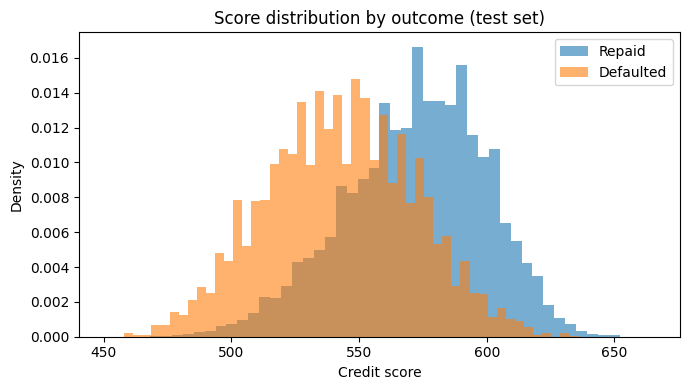

,applicants,default_rate
band,,
<520,3298,33.38%
520-559,17681,13.66%
560-599,31421,4.25%
600-639,9022,1.26%
640-679,81,0.00%


In [60]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

def pd_to_score(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.round(offset + factor * np.log((1 - p) / p)).astype(int)

scores = pd_to_score(p_test_gbm)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores[y_test.values == 0], bins=50, alpha=0.6, density=True, label="Repaid")
ax.hist(scores[y_test.values == 1], bins=50, alpha=0.6, density=True, label="Defaulted")
ax.set_xlabel("Credit score"); ax.set_ylabel("Density")
ax.set_title("Score distribution by outcome (test set)"); ax.legend()
plt.tight_layout(); plt.show()

score_bands = pd.DataFrame({"score": scores, "default": y_test.values})
score_bands["band"] = pd.cut(score_bands["score"], bins=[-np.inf, 520, 560, 600, 640, 680, np.inf],
                             labels=["<520", "520-559", "560-599", "600-639", "640-679", "680+"], right=False)
score_bands.groupby("band", observed=True)["default"].agg(applicants="size", default_rate="mean") \
    .style.format({"default_rate": "{:.2%}"})

## 13. Summary

In [61]:
summary = test_results.set_index("model")
full_gini = summary.loc["LightGBM", "Gini"]
thin_gini = summary.loc["LightGBM, no bureau data", "Gini"]
lr_gini   = summary.loc["Logistic regression", "Gini"]

print(f"Logistic regression Gini:        {lr_gini:.3f}")
print(f"LightGBM Gini:                   {full_gini:.3f}  ({full_gini - lr_gini:+.3f} vs baseline)")
print(f"LightGBM without bureau data:    {thin_gini:.3f}")
if full_gini > 0:
    print(f"Share of predictive power kept without bureau data: {thin_gini / full_gini:.0%}")

Logistic regression Gini:        0.504
LightGBM Gini:                   0.538  (+0.034 vs baseline)
LightGBM without bureau data:    0.433
Share of predictive power kept without bureau data: 80%


### Write-up

**Problem.** Millions of people have no credit history, so lenders cannot assess them. Using the Home Credit dataset, I tested how well repayment can be predicted, including without bureau-style data, and whether the model treats age and gender groups fairly.

**Approach.** Cleaned anomalies, engineered affordability and stability features, built a logistic regression baseline and a LightGBM challenger, evaluated on a held-out test set, checked calibration, explained predictions with SHAP, tested fairness by gender and age, and ran an experiment removing age features.

**Results.**
- Logistic regression Gini 0.504; LightGBM Gini 0.538 (AUC 0.769, KS 0.402).
- Without bureau-style data, Gini 0.433, about **80%** of the full model's predictive power retained.
- Top drivers: external scores (`EXT_SOURCE_*`), organization type, and engineered features such as credit term and credit-to-goods ratio.
- Fairness (approve safest 80%): applicants under 30 who would have repaid were falsely rejected 30.7% of the time vs 5.7% for those 60+. By gender, false rejections were 22.2% for men vs 14.5% for women.
- Removing age features cost almost no accuracy (Gini 0.538 to 0.533) but **widened** the age false-rejection gap from 25.0 to 27.7 points. Features strongly correlated with age, including the employment anomaly flag (0.62), employer phone flag (0.62) and `EXT_SOURCE_1` (0.60), act as proxies.

**Takeaway.** Alternative data retains most predictive power for thin-file applicants, but hiding sensitive variables does not make a model fair. Young applicants are disadvantaged largely because they lack history, so new data that gives them a track record is likely a better fix than removing variables.

**Limitations.** No dates, so no out-of-time validation; reject inference not addressed; fairness tested on two attributes only.

**Next steps.** Fairness-aware training and threshold methods where legally permitted; add bureau and previous-application tables; monotonic constraints.
